# 01 - Dataset Review
**Project:** AI-Assisted Phishing Email Detection · **Phase:** Week 1

Goal: load the Kaggle *Phishing Email Dataset* files, inspect schema and quality, and document limitations before finalizing.

In [2]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data.loading import RAW_DIR, load_raw
pd.set_option('display.max_colwidth', 120)
sns.set_theme()

## 1. Raw files and schemas
Each CSV may use a different schema; this cell lists them.

In [3]:
for f in sorted(RAW_DIR.glob('*.csv')):
    try:
        d = pd.read_csv(f, nrows=3)
    except UnicodeDecodeError:
        d = pd.read_csv(f, nrows=3, encoding='latin-1')
    print(f.name, '->', list(d.columns))

CEAS_08.csv -> ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
Enron.csv -> ['subject', 'body', 'label']
Ling.csv -> ['subject', 'body', 'label']
Nazario.csv -> ['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label']
Nigerian_Fraud.csv -> ['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label']
PhishingEmailData.csv -> ['Email_Subject', 'Email_Content', 'Sending_Date', 'Sending_Time', 'Day', 'URL_Title', 'Coined.Word', 'Sender_Name', 'Sender_Title', 'Closing_Remarks', 'Sender_Email ', 'Logo', 'To']
SpamAssasin.csv -> ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
spamResults.csv -> ['message', 'compound', 'neg', 'neu', 'pos']


## 2. Load and standardize

In [4]:
df = load_raw()
print(df.shape)
df.head()

Skipped (not raw labeled email data): ['spamResults']
(82675, 5)


,source,subject,body,text,label
0,CEAS_08,Never agree to be a loser,"Buck up, your troubles caused by small dimension will soon be over!\nBecome a lover no woman will be able to resist!...","Never agree to be a loser Buck up, your troubles caused by small dimension will soon be over!\nBecome a lover no wom...",1
1,CEAS_08,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these techniques http://www.brightmade.com\n\n\n,Befriend Jenna Jameson \nUpgrade your sex and pleasures with these techniques http://www.brightmade.com,1
2,CEAS_08,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TOP 10 >from CNN.com >Top videos and storie...,CNN.com Daily Top 10 >+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TOP 10 >from CNN.com >...,1
3,CEAS_08,Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail/SpamAssassin/Util/R...,Would anyone object to removing .so from this list? The .so TLD is \nbasically dead and we've found that lots of b...,Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail/SpamAssassin/Util/R...,0
4,CEAS_08,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore.com/y1pXdX3kwzhBa8xhXv8tdHbjHn7Tj4VT91YQg5lB5-...,SpecialPricesPharmMoreinfo \nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore.com/y1pXdX3kwzhBa8x...,1


## 3. Label balance (overall and per source)

label
1    43080
0    39595
Name: count, dtype: int64
label                  0      1
source                         
CEAS_08            17312  21842
Enron              15791  13976
Ling                2401    458
Nazario                0   1565
Nigerian_Fraud         0   3332
PhishingEmailData      0    189
SpamAssasin         4091   1718


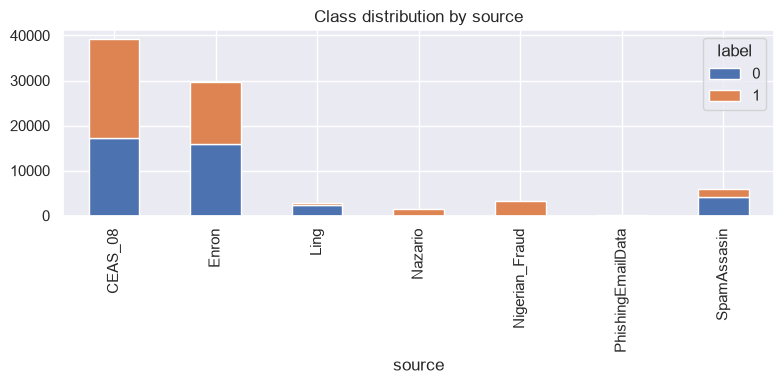

In [5]:
print(df['label'].value_counts(dropna=False))
print(pd.crosstab(df['source'], df['label'], dropna=False))
ax = pd.crosstab(df['source'], df['label']).plot(kind='bar', stacked=True, figsize=(8,4), title='Class distribution by source')
plt.tight_layout(); plt.savefig('../reports/figures/class_by_source.png', dpi=150)

> **Why this matters:** if a source contains only one class (e.g. Nazario = phishing only, Enron = legitimate only), a model can learn *which source an email came from* rather than *what phishing looks like*. Record this in the dataset card.

## 4. Data quality checks

In [6]:
q = pd.DataFrame({
    'missing_label': [df['label'].isna().sum()],
    'empty_text': [(df['text'].str.strip()=='').sum()],
    'exact_duplicates': [df.duplicated('text').sum()],
    'dup_pct': [round(100*df.duplicated('text').mean(), 2)],
})
q

,missing_label,empty_text,exact_duplicates,dup_pct
0,0,0,46,0.06


In [7]:
# Duplicates with conflicting labels
g = df.groupby('text')['label'].nunique()
print('texts with conflicting labels:', (g > 1).sum())

texts with conflicting labels: 0


## 5. Text length and content

label                      0             1
n_chars count   39595.000000  4.308000e+04
        mean     2199.035939  1.417828e+03
        std      5386.493869  2.285561e+04
        min        16.000000  3.000000e+00
        25%       566.000000  2.430000e+02
        50%      1116.000000  4.980000e+02
        75%      2177.000000  1.486000e+03
        max    299272.000000  4.599694e+06
n_urls  count   39595.000000  4.308000e+04
        mean        2.434045  3.763231e+00
        std        26.255451  1.233119e+01
        min         0.000000  0.000000e+00
        25%         0.000000  0.000000e+00
        50%         0.000000  0.000000e+00
        75%         2.000000  1.000000e+00
        max      4620.000000  4.960000e+02


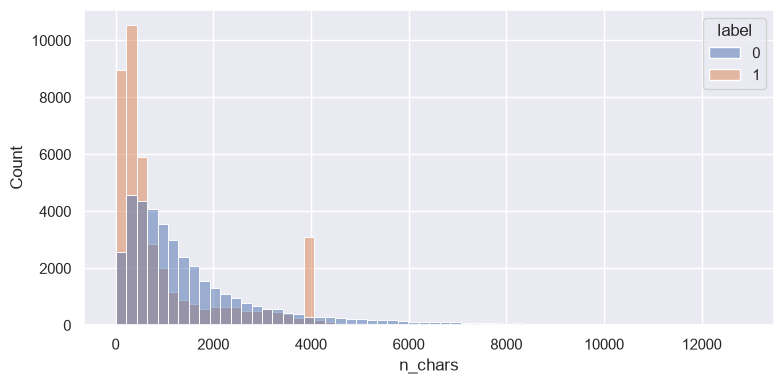

In [8]:
df['n_chars'] = df['text'].str.len()
df['n_urls'] = df['text'].str.count(r'https?://|www\.')
print(df.groupby('label')[['n_chars','n_urls']].describe().T)
fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(data=df[df.n_chars < df.n_chars.quantile(.99)], x='n_chars', hue='label', bins=60, ax=ax)
plt.tight_layout(); plt.savefig('../reports/figures/length_by_label.png', dpi=150)

In [9]:
# Spot-check a few examples per class (label verification)
for lbl in [0, 1]:
    print(f'\n=== label {lbl} ===')
    for t in df[df.label==lbl].sample(3, random_state=1)['text']:
        print('-', t[:250].replace('\n',' '), '\n')


=== label 0 ===
- Scholarships & Awards Advertised - 9 April 2008 This week's scholarships advertisement can be viewed at http://awards.massey.ac.nz/. Please go to Latest Adverts tab on the left column.    Listing of scholarships advertised : PhD Scholarship in Endoph 

- Re: [ILUG] Where to buy new PC without OS ? dxklu@eillo.org wrote: > You can always order the parts from Komlpett yourself and just put it > together . . .  >  > I used to do that - you get exactly what you want and it works out cheaper > as well. Im 

- [UAI] Postdoctoral position in coordination languages and web services [ Our apologies for multiple copies ]  -----------------------------------------------------------------------------                             Call for applications              


=== label 1 ===
- Penis Enlargment Reviews  Size DOES matter - change your life today!  "Ever since I started on your herbal supplement, Sharon says sex is so much more pleasurable for her, and she comes much more eas

## 6. Notes for the dataset card
Fill in `reports/dataset_card.md` from the outputs above: sources, size, balance, duplicates, source bias, limitations.

In [10]:
d = pd.read_csv(RAW_DIR / "PhishingEmailData.csv", encoding='latin-1')
print(d.shape)
for c in d.columns:
    print(c, '-> nulls:', d[c].isna().sum(), '| unique sample:', d[c].dropna().unique()[:5])

(189, 13)
Email_Subject -> nulls: 1 | unique sample: <ArrowStringArray>
[                                  'URGENT REQUEST',
                                   'Quick question',
 '******Part time home work assistant needed******',
                                 'Ê vendor payment',
                                 '  Quick question']
Length: 5, dtype: str
Email_Content -> nulls: 0 | unique sample: <ArrowStringArray>
[                                                                                                                                                                                                                                                                          'Are you available ?\nNo calls text only 9513072XXX',
                                                                                                                                                                                                                                                                'I